In [3]:
import numpy as np

def modelo_banda(t, A, beta, gamma, t0, tau_rise, tau_fall):
    """Ecuación 1 del paper, para una banda. t y t0 en días."""
    dt = t - t0
    subida = A / (1 + np.exp(-dt / tau_rise))
    plateau = 1 - beta * dt
    caida = (1 - beta * gamma) * np.exp((gamma - dt) / tau_fall)
    return subida * np.where(dt < gamma, plateau, caida)

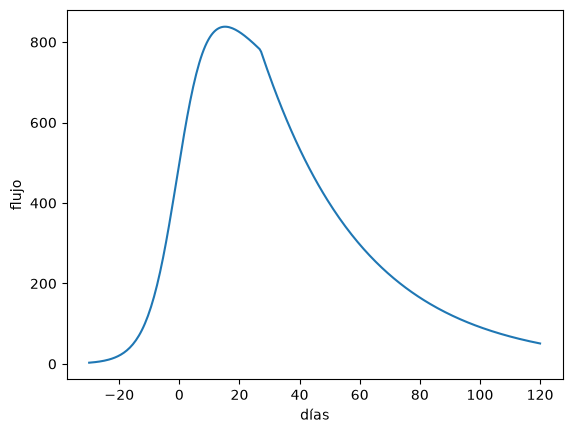

In [4]:
import matplotlib.pyplot as plt

t = np.linspace(-30, 120, 300)
f = modelo_banda(t, A=1000, beta=0.008, gamma=27, t0=0, tau_rise=5, tau_fall=34)
plt.plot(t, f); plt.xlabel("días"); plt.ylabel("flujo"); plt.show()

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw")
PROC = Path("../data/processed")

In [8]:
fig4 = ["ZTF20acbeanu", "ZTF23aacxofz", "ZTF21aajgdeu", "ZTF20aadtarr", "ZTF20acpyldh", "ZTF21abpwtde"]
print([n for n in fig4 if (PROC / f"{n}.parquet").exists()])

['ZTF20acbeanu', 'ZTF23aacxofz', 'ZTF21aajgdeu', 'ZTF20aadtarr', 'ZTF20acpyldh']


In [11]:
muestra = pd.read_csv("../data/muestra.csv")

clases_fig4 = pd.DataFrame({"NAME": fig4}).merge(
    muestra[["NAME", "LABEL", "CLASE"]],
    on="NAME",
    how="left"
)

display(clases_fig4)

,NAME,LABEL,CLASE
0,ZTF20acbeanu,SN Ia,SN Ia
1,ZTF23aacxofz,SN Ia,SN Ia
2,ZTF21aajgdeu,SN IIP,SN II
3,ZTF20aadtarr,SN IIn,SN IIn
4,ZTF20acpyldh,SLSN-I,SLSN-I
5,ZTF21abpwtde,NaN,NaN


In [14]:
def ajusta_banda(c, t_ref):
    t = c["mjd"].to_numpy() - t_ref            
    f = c["flujo"].to_numpy()
    e = c["flujo_err"].to_numpy()
    fm = f.max()
    p0  = [1.25 * fm, 0.0083, 27, -18, 4.7, 34]       
    inf = [0.5 * fm, 1e-4, 1.0, -100, 0.01, 1.0]      
    sup = [3.16 * fm, 0.03, 3162, 30, 1e4, 1e4]
    popt, _ = curve_fit(modelo_banda, t, f, p0=p0, sigma=e,
                        bounds=(inf, sup), maxfev=20000)
    chi2 = np.mean(((f - modelo_banda(t, *popt)) / e) ** 2)
    # cuántos parámetros terminaron pegados a un límite
    n_lim = int(np.sum(np.isclose(popt, inf, rtol=1e-3, atol=1e-6) |
                       np.isclose(popt, sup, rtol=1e-3, atol=1e-6)))
    return popt, chi2, t, n_lim


g {'A': 2018.782, 'beta': 0.0, 'gamma': 11.413, 't0': -4.913, 'tau_rise': 2.398, 'tau_fall': 10.573} chi2: 0.35 | parámetros en el límite: 1
r {'A': 2045.9, 'beta': 0.019, 'gamma': 12.324, 't0': -4.343, 'tau_rise': 2.589, 'tau_fall': 22.344} chi2: 0.43 | parámetros en el límite: 0


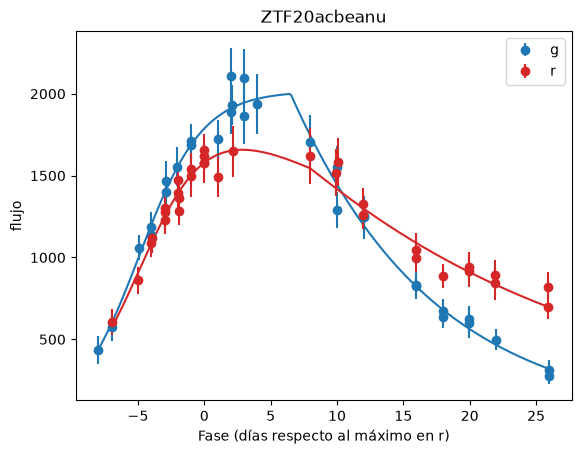

In [17]:
NOMBRES = ["A", "beta", "gamma", "t0", "tau_rise", "tau_fall"]

nombre = "ZTF20acbeanu"
curva = pd.read_parquet(PROC / f"{nombre}.parquet")
cr = curva[curva["banda"] == "r"]
t_ref = cr["mjd"].to_numpy()[cr["flujo"].to_numpy().argmax()]   

colores = {"g": "tab:blue", "r": "tab:red"}
for b, c in curva.groupby("banda"):
    try:
        popt, chi2, t, n_lim = ajusta_banda(c, t_ref)
    except (RuntimeError, ValueError) as e:
        print(b, "no convergió:", e)
        continue
    print(b, {k: round(float(v), 3) for k, v in zip(NOMBRES, popt)},
          "chi2:", round(float(chi2), 2), "| parámetros en el límite:", n_lim)
    tg = np.linspace(t.min(), t.max(), 300)
    plt.errorbar(t, c["flujo"], yerr=c["flujo_err"], fmt="o", color=colores[b], label=b)
    plt.plot(tg, modelo_banda(tg, *popt), color=colores[b])

plt.xlabel("Fase (días respecto al máximo en r)")
plt.ylabel("flujo")
plt.title(nombre)
plt.legend()
plt.show()

g {'A': 808.774, 'beta': 0.006, 'gamma': 16.435, 't0': -12.416, 'tau_rise': 2.152, 'tau_fall': 37.951} chi2: 0.22 | parámetros en el límite: 0
r {'A': 2036.283, 'beta': 0.016, 'gamma': 10.972, 't0': -12.84, 'tau_rise': 4.791, 'tau_fall': 105.08} chi2: 0.7 | parámetros en el límite: 0


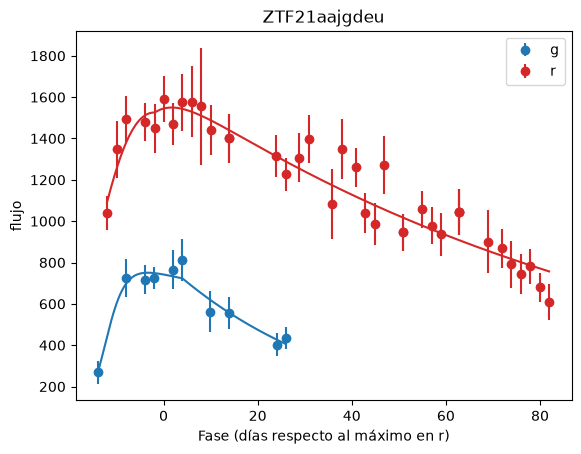

In [22]:
nombre = "ZTF21aajgdeu"
curva = pd.read_parquet(PROC / f"{nombre}.parquet")
cr = curva[curva["banda"] == "r"]
t_ref = cr["mjd"].to_numpy()[cr["flujo"].to_numpy().argmax()]   # máximo en r

colores = {"g": "tab:blue", "r": "tab:red"}
for b, c in curva.groupby("banda"):
    try:
        popt, chi2, t, n_lim = ajusta_banda(c, t_ref)
    except (RuntimeError, ValueError) as e:
        print(b, "no convergió:", e)
        continue
    print(b, {k: round(float(v), 3) for k, v in zip(NOMBRES, popt)},
          "chi2:", round(float(chi2), 2), "| parámetros en el límite:", n_lim)
    tg = np.linspace(t.min(), t.max(), 300)
    plt.errorbar(t, c["flujo"], yerr=c["flujo_err"], fmt="o", color=colores[b], label=b)
    plt.plot(tg, modelo_banda(tg, *popt), color=colores[b])

plt.xlabel("Fase (días respecto al máximo en r)")
plt.ylabel("flujo")
plt.title(nombre)
plt.legend()
plt.show()

g {'A': 2599.668, 'beta': 0.007, 'gamma': 75.116, 't0': -32.631, 'tau_rise': 5.327, 'tau_fall': 123.99} chi2: 0.26 | parámetros en el límite: 0
r {'A': 2545.833, 'beta': 0.004, 'gamma': 125.435, 't0': -32.715, 'tau_rise': 5.699, 'tau_fall': 237.588} chi2: 0.2 | parámetros en el límite: 0


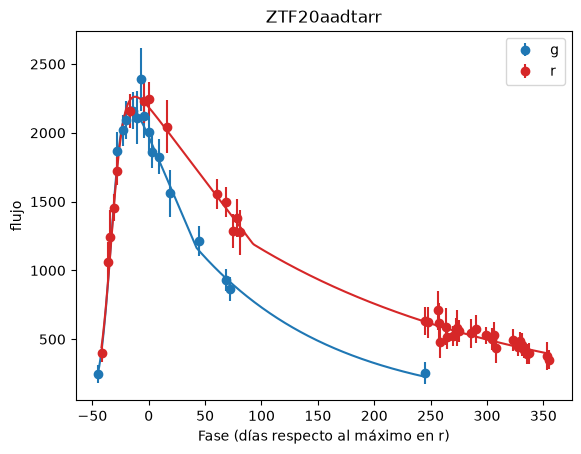

In [23]:
nombre = "ZTF20aadtarr"
curva = pd.read_parquet(PROC / f"{nombre}.parquet")
cr = curva[curva["banda"] == "r"]
t_ref = cr["mjd"].to_numpy()[cr["flujo"].to_numpy().argmax()]   # máximo en r

colores = {"g": "tab:blue", "r": "tab:red"}
for b, c in curva.groupby("banda"):
    try:
        popt, chi2, t, n_lim = ajusta_banda(c, t_ref)
    except (RuntimeError, ValueError) as e:
        print(b, "no convergió:", e)
        continue
    print(b, {k: round(float(v), 3) for k, v in zip(NOMBRES, popt)},
          "chi2:", round(float(chi2), 2), "| parámetros en el límite:", n_lim)
    tg = np.linspace(t.min(), t.max(), 300)
    plt.errorbar(t, c["flujo"], yerr=c["flujo_err"], fmt="o", color=colores[b], label=b)
    plt.plot(tg, modelo_banda(tg, *popt), color=colores[b])

plt.xlabel("Fase (días respecto al máximo en r)")
plt.ylabel("flujo")
plt.title(nombre)
plt.legend()
plt.show()

g {'A': 1537.188, 'beta': 0.0, 'gamma': 1.0, 't0': 12.108, 'tau_rise': 90.235, 'tau_fall': 45.566} chi2: 0.4 | parámetros en el límite: 2
r {'A': 762.733, 'beta': 0.001, 'gamma': 118.097, 't0': -100.0, 'tau_rise': 40.903, 'tau_fall': 50.163} chi2: 1.01 | parámetros en el límite: 1


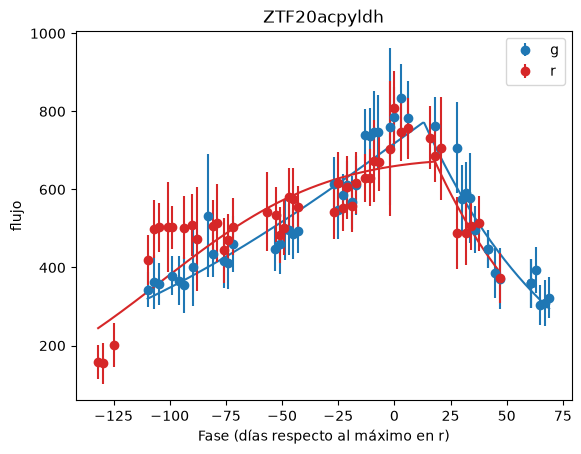

In [24]:
nombre = "ZTF20acpyldh"
curva = pd.read_parquet(PROC / f"{nombre}.parquet")
cr = curva[curva["banda"] == "r"]
t_ref = cr["mjd"].to_numpy()[cr["flujo"].to_numpy().argmax()]   # máximo en r

colores = {"g": "tab:blue", "r": "tab:red"}
for b, c in curva.groupby("banda"):
    try:
        popt, chi2, t, n_lim = ajusta_banda(c, t_ref)
    except (RuntimeError, ValueError) as e:
        print(b, "no convergió:", e)
        continue
    print(b, {k: round(float(v), 3) for k, v in zip(NOMBRES, popt)},
          "chi2:", round(float(chi2), 2), "| parámetros en el límite:", n_lim)
    tg = np.linspace(t.min(), t.max(), 300)
    plt.errorbar(t, c["flujo"], yerr=c["flujo_err"], fmt="o", color=colores[b], label=b)
    plt.plot(tg, modelo_banda(tg, *popt), color=colores[b])

plt.xlabel("Fase (días respecto al máximo en r)")
plt.ylabel("flujo")
plt.title(nombre)
plt.legend()
plt.show()

In [28]:

from joblib import Parallel, delayed

def ajusta_curva(nombre):
    curva = pd.read_parquet(PROC / f"{nombre}.parquet")
    cr = curva[curva["banda"] == "r"]
    t_ref = cr["mjd"].to_numpy()[cr["flujo"].to_numpy().argmax()]
    out = {"NAME": nombre}
    for b in ["g", "r"]:
        c = curva[curva["banda"] == b]
        try:
            popt, chi2, _, nlim = ajusta_banda(c, t_ref)
        except (RuntimeError, ValueError):
            return {"NAME": nombre, "ok": False}
        for k, v in zip(NOMBRES, popt):
            out[f"{k}_{b}"] = v
        out[f"chi2_{b}"] = chi2
        out[f"nlim_{b}"] = nlim
    out["ok"] = True
    return out

nombres = sorted(p.stem for p in PROC.glob("*.parquet"))
print(len(nombres), "curvas a ajustar")

resultados = Parallel(n_jobs=-1)(delayed(ajusta_curva)(n) for n in nombres)
ajustes = pd.DataFrame(resultados)
ajustes.to_csv("../data/ajustes.csv", index=False)
print(ajustes["ok"].value_counts())

5224 curvas a ajustar


/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9: OptimizeWarning: Covariance of the parameters could not be estimated
/tmp/ipykernel_20498/1204932738.py:9:

ok
True     5223
False       1
Name: count, dtype: int64


In [29]:
muestra = pd.read_csv("../data/muestra.csv")

print(ajustes["ok"].value_counts())

buenos = ajustes[ajustes["ok"]].merge(muestra[["NAME", "CLASE"]], on="NAME")
print(buenos.groupby("CLASE")[["chi2_g", "chi2_r"]].median().round(2))
print(buenos[["chi2_g", "chi2_r"]].describe().round(2))

buenos["con_limite"] = (buenos["nlim_g"] > 0) | (buenos["nlim_r"] > 0)
print(buenos.groupby("CLASE")["con_limite"].mean().round(2))

ok
True     5223
False       1
Name: count, dtype: int64
         chi2_g  chi2_r
CLASE                  
SLSN-I     0.21    0.23
SN II      0.33    0.42
SN IIn     0.25    0.31
SN Ia      0.16    0.34
SN Ib/c    0.26    0.40
        chi2_g   chi2_r
count  5223.00  5223.00
mean      2.33     1.85
std      34.09    30.35
min       0.00     0.00
25%       0.09     0.18
50%       0.19     0.35
75%       0.39     0.78
max    1596.64  1748.37
CLASE
SLSN-I     0.61
SN II      0.47
SN IIn     0.41
SN Ia      0.64
SN Ib/c    0.66
Name: con_limite, dtype: float64


In [30]:
lims = {"beta": (1e-4, 0.03), "gamma": (1.0, 3162), "t0": (-100, 30),
        "tau_rise": (0.01, 1e4), "tau_fall": (1.0, 1e4)}
filas = []
for b in ["g", "r"]:
    for p, (lo, hi) in lims.items():
        col = buenos[f"{p}_{b}"]
        filas.append({"parametro": f"{p}_{b}",
                      "en_minimo": np.isclose(col, lo, rtol=1e-3, atol=1e-6).mean(),
                      "en_maximo": np.isclose(col, hi, rtol=1e-3, atol=1e-6).mean()})
print(pd.DataFrame(filas).round(3).to_string(index=False))

 parametro  en_minimo  en_maximo
    beta_g      0.143      0.219
   gamma_g      0.033      0.001
      t0_g      0.002      0.003
tau_rise_g      0.003      0.008
tau_fall_g      0.002      0.002
    beta_r      0.292      0.075
   gamma_r      0.045      0.000
      t0_r      0.002      0.009
tau_rise_r      0.001      0.002
tau_fall_r      0.001      0.001


In [31]:
npts = []
for n in buenos["NAME"]:
    c = pd.read_parquet(PROC / f"{n}.parquet")
    npts.append((n, (c["banda"] == "g").sum(), (c["banda"] == "r").sum()))
buenos = buenos.merge(pd.DataFrame(npts, columns=["NAME", "n_g", "n_r"]), on="NAME")

print("curvas con <= 8 puntos en g:", (buenos["n_g"] <= 8).mean().round(3),
      "| en r:", (buenos["n_r"] <= 8).mean().round(3))
print(buenos.groupby(pd.cut(buenos["n_g"], [0, 6, 8, 12, 20, 50, 1000]),
                     observed=True)["chi2_g"].median().round(2))

buenos["chi2_max"] = buenos[["chi2_g", "chi2_r"]].max(axis=1)
print("chi2 > 1.2:", (buenos["chi2_max"] > 1.2).sum(), "curvas,",
      (buenos["chi2_max"] > 1.2).mean().round(3))

curvas con <= 8 puntos en g: 0.308 | en r: 0.174
n_g
(0, 6]        0.10
(6, 8]        0.12
(8, 12]       0.15
(12, 20]      0.21
(20, 50]      0.31
(50, 1000]    0.49
Name: chi2_g, dtype: float64
chi2 > 1.2: 1089 curvas, 0.209


0.50     0.32
0.75     0.68
0.90     1.74
0.95     3.67
0.99    18.95
Name: chi2_conj, dtype: float64
chi2_conj > 1.2: 757 curvas, 0.145
chi2_conj > 2: 463 curvas, 0.089
chi2_conj > 3: 321 curvas, 0.061
chi2_conj > 5: 198 curvas, 0.038
CLASE
SLSN-I     0.21
SN II      0.43
SN IIn     0.30
SN Ia      0.31
SN Ib/c    0.41
Name: chi2_conj, dtype: float64


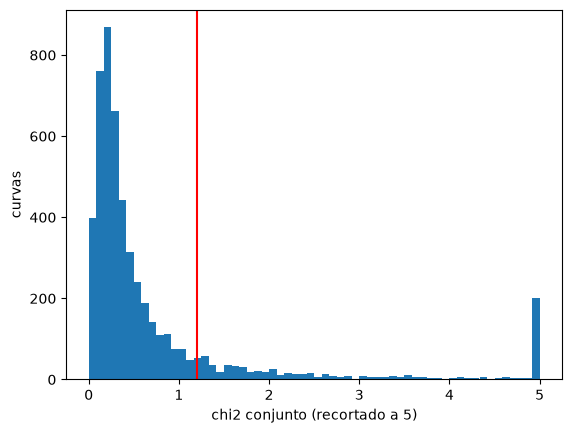

In [32]:
buenos["chi2_conj"] = (buenos["n_g"] * buenos["chi2_g"] + buenos["n_r"] * buenos["chi2_r"]) / (buenos["n_g"] + buenos["n_r"])

print(buenos["chi2_conj"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]).round(2))
for u in [1.2, 2, 3, 5]:
    print(f"chi2_conj > {u}:", (buenos["chi2_conj"] > u).sum(), "curvas,", (buenos["chi2_conj"] > u).mean().round(3))
print(buenos.groupby("CLASE")["chi2_conj"].median().round(2))

plt.hist(buenos["chi2_conj"].clip(upper=5), bins=60)
plt.axvline(1.2, color="r"); plt.xlabel("chi2 conjunto (recortado a 5)"); plt.ylabel("curvas")
plt.show()

In [33]:
CORTE = 3.0
sel = buenos[buenos["chi2_conj"] <= CORTE].copy()
print(len(buenos), "->", len(sel))

antes = buenos["CLASE"].value_counts()
despues = sel["CLASE"].value_counts()
print(pd.DataFrame({"antes": antes, "despues": despues,
                    "eliminada": (1 - despues / antes).round(3)}))

X = pd.DataFrame({"NAME": sel["NAME"].values, "CLASE": sel["CLASE"].values})
for p in ["beta", "gamma", "tau_rise", "tau_fall"]:          # banda r: 4 features
    X[f"{p}_r"] = sel[f"{p}_r"].values
for p in ["A", "beta", "gamma", "tau_rise", "tau_fall"]:     # banda g: log-razón g/r, 5 features
    X[f"{p}_g"] = np.log10(sel[f"{p}_g"].values / sel[f"{p}_r"].values)
X["t0_g"] = (sel["t0_g"] - sel["t0_r"]).values               # retraso entre bandas (días)

print(X.shape)
X.to_csv("../data/features.csv", index=False)

5223 -> 4902
         antes  despues  eliminada
CLASE                             
SN Ia     3897     3694      0.052
SN II      838      763      0.089
SN Ib/c    213      189      0.113
SN IIn     204      187      0.083
SLSN-I      71       69      0.028
(4902, 12)
